In [ ]:
import csv
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw


In [10]:
# Load in molecule data
molecule_data = pd.read_csv('../data/raw/CHEMBL_30_10_2026.csv', sep='";"', engine="python", quoting=csv.QUOTE_NONE)

# The first column header/values start with ", the last end with ".
molecule_data.columns = molecule_data.columns.str.strip('"').str.strip()
for col in (molecule_data.columns[0], molecule_data.columns[-1]):
    molecule_data[col] = molecule_data[col].astype("string").str.strip('"')

molecule_data = molecule_data.rename(
        columns={"Compound ChEMBL ID": "ChEMBL ID"})

# Load in experimental data
experimental_data = pd.read_csv('../data/raw/CHEMBL_01_11_2026.csv', sep='";"', engine="python", quoting=csv.QUOTE_NONE)

experimental_data.columns = experimental_data.columns.str.strip('"').str.strip()
for col in (molecule_data.columns[0], molecule_data.columns[-1]):
    molecule_data[col] = molecule_data[col].astype("string").str.strip('"')

experimental_data = experimental_data.rename(
        columns={"Molecule ChEMBL ID": "ChEMBL ID"})

mol_cols = ["ChEMBL ID"] + [c for c in molecule_data.columns
                                if c not in experimental_data.columns and c != "ChEMBL ID"]

data = experimental_data.merge(molecule_data[mol_cols], on="ChEMBL ID", how="left",
                     validate="many_to_one", indicator=True)
print(data.shape)

# Remove empty columns
for column in data.columns:
    if data[column].isna().sum() == len(data):
        data = data.drop(column, axis = 'columns')

print(data.shape)
print(data.isna().sum())


(4200, 74)
(4200, 25)
ChEMBL ID                 0
Molecule Name          3549
Molecule Max Phase     3624
Molecular Weight          0
#RO5 Violations          11
AlogP                    11
Compound Key              0
Smiles                    0
Standard Type             0
Standard Value            0
Potential Duplicate       0
Assay ChEMBL ID           0
Assay Description         0
Assay Type                0
BAO Format ID             0
BAO Label                 0
Target ChEMBL ID          0
Target Name               0
Target Type               0
Document ChEMBL ID        0
Source ID                 0
Source Name               0
Value                     0
Modality                  0
_merge                    0
dtype: int64


In [11]:
print(data["Standard Type"].value_counts())
print(data["Assay ChEMBL ID"].nunique(), data["Document ChEMBL ID"].nunique())
print(data["Assay ChEMBL ID"].value_counts().head())
print(pd.to_numeric(data["Standard Value"], errors="coerce").describe())
print((pd.to_numeric(data["Standard Value"], errors="coerce") == pd.to_numeric(data["Value"], errors="coerce")).mean())
print(data["Potential Duplicate"].value_counts())
print(data["ChEMBL ID"].duplicated().sum())

Standard Type
LogD7.4    4200
Name: count, dtype: int64
1 1
Assay ChEMBL ID
CHEMBL3301363    4200
Name: count, dtype: int64
count    4200.000000
mean        2.186336
std         1.203004
min        -1.500000
25%         1.410000
50%         2.360000
75%         3.100000
max         4.500000
Name: Standard Value, dtype: float64
1.0
Potential Duplicate
0    4200
Name: count, dtype: int64
5


Type
Small molecule    5784
Protein              9
Unknown              1
Name: count, dtype: int64


KeyError: 'Type'

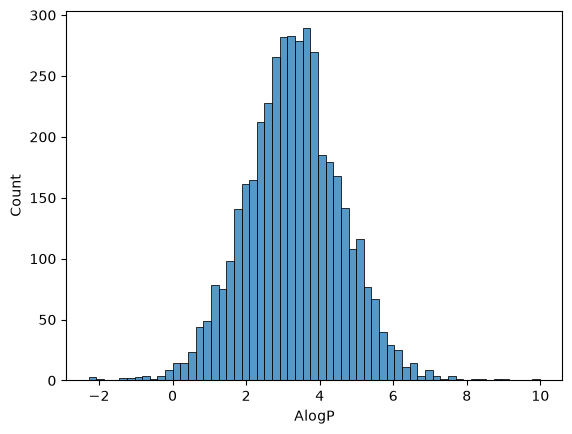

In [13]:
# Explore target variable distribution
sns.histplot(data = data, x = 'AlogP')

# Explore entry types
print(molecule_data['Type'].value_counts(dropna = False))

# Remove entries of non-small molecules
data_clean = data[data['Type'] == 'Small molecule']
data_clean = data[['ChEMBL ID', 'Smiles', 'AlogP']]
print(data.shape)


In [16]:
# with no H, Cl, Br or I attached.
_CF3 = Chem.MolFromSmarts("[CX4;H0](F)(F)F")
_CF2 = Chem.MolFromSmarts("[CX4;H0](F)(F)([!#9;!#17;!#35;!#53])[!#9;!#17;!#35;!#53]")


def fluorine_stats(smiles) -> pd.DataFrame:
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        carbons = ({x[0] for x in m.GetSubstructMatches(_CF3)}
                   | {x[0] for x in m.GetSubstructMatches(_CF2)})
        rows.append({"n_F": sum(a.GetAtomicNum() == 9 for a in m.GetAtoms()),
                     "n_cf_carbons": len(carbons)})
    out = pd.DataFrame(rows)
    out["pfas_oecd"] = out["n_cf_carbons"] > 0
    return out

fs = fluorine_stats(data["Smiles"])
print(pd.cut(fs["n_cf_carbons"], [-1, 0, 1, 3, 10_000], labels=["0", "1", "2-3", "4+"]).value_counts().sort_index())
print(data.loc[fs["n_cf_carbons"] >= 2, "Smiles"].head(10).tolist())

n_cf_carbons
0      3893
1       290
2-3      17
4+        0
Name: count, dtype: int64
['Fc1cccc(C(COCc2cc(C(F)(F)F)cc(C(F)(F)F)c2)N2CCNCC2)c1', 'CC(C)C(NC(=O)Cn1c(-c2cccs2)ncc(NC(=O)OCC(F)(F)F)c1=O)C(=O)C(F)(F)F', 'FC(F)(F)c1cc(CO[C@H]2CCCN[C@H]2c2ccccc2)cc(C(F)(F)F)c1', 'CC(C)C(NC(=O)Cn1c(-c2ccccc2)ncc(NC(=O)OCC(F)(F)F)c1=O)C(=O)C(F)(F)F', 'NC(=O)c1cc(C(N)=O)n(-c2cccc(-c3cc(C(F)(F)F)ccc3C(F)(F)F)c2)n1', 'C[C@H]1O[C@@H](n2cnc3c(N)nc(OCC4CC(F)(F)C4(F)F)nc32)[C@H](O)[C@@H]1O', 'O=C(Nc1cc(C(F)(F)F)cc(C(F)(F)F)c1)c1cnc(Cl)nc1C(F)(F)F', 'FC(F)(F)c1cc(COCC(c2ccccc2)N2CCNCC2)cc(C(F)(F)F)c1', 'Fc1ccc(C(COCc2cc(C(F)(F)F)cc(C(F)(F)F)c2)N2CCNCC2)cc1', 'O=S(=O)(c1ccccc1)N(CC(F)(F)F)c1ccc(C(O)(C(F)(F)F)C(F)(F)F)cc1']


In [9]:
ad = pd.read_parquet("../results/tables/ad_scores.parquet")
test = ad[ad["subset"] == "test"]

# median per seed, then mean and SD over the 5 seeds
per_seed = test.groupby(["method", "seed"])["max_sim"].median()
print(per_seed.groupby("method").agg(["mean", "std"]).round(3))

# fraction of test molecules at or above 0.4, and inside the kNN domain
print(test.groupby("method")[["near_train", "in_ad"]].mean().round(3))

pf = pd.read_csv("../results/tables/pfas_coverage.csv")
print(pf["max_sim"].median(), pf["near_train"].mean(), pf["in_ad"].mean())

           mean    std
method                
cluster   0.365  0.012
random    0.681  0.012
scaffold  0.564  0.022
          near_train  in_ad
method                     
cluster        0.353  0.858
random         0.811  0.942
scaffold       0.736  0.934
0.190476194024086 0.031541218637992835 0.12703533026113673


In [ ]:
# Load in PFAS data and compute some basic stats
from qsar_ad.domain import load_pfas

pd.set_option("display.width", 200, "display.max_columns", None, "display.max_colwidth", 80)

# Same standardization as the analysis script, so rows and InChIKeys match
pfas, counts = load_pfas("../data/raw/Chemical List PFASSTRUCT-2026-11-12.csv", smiles_col="SMILES")
cov = pd.read_csv("../results/tables/pfas_coverage.csv")
print(counts, len(cov))

extra = [c for c in ["inchikey", "smiles", "PREFERRED NAME", "CASRN"] if c in pfas.columns]
d = cov.merge(pfas[extra], on="inchikey", how="left", validate="one_to_one")
assert d["smiles"].notna().all()

d["mol"] = d["smiles"].map(Chem.MolFromSmiles)
d["heavy_atoms"] = d["mol"].map(lambda m: m.GetNumHeavyAtoms())
d["mol_wt"] = d["mol"].map(Descriptors.MolWt)
d["zero_cf"] = d["n_cf_carbons"] == 0
print(d["zero_cf"].sum(), "molecules in the 0-carbon group of", len(d))

{'rows_in': 21029, 'no_or_failed_structure': 30, 'after_dedup': 19530} 19530
1692 molecules in the 0-carbon group of 19530


In [12]:
# Explore the 0-carbon group for common structural motifs that might be relevant to QSAR applicability domain
def has(m, smarts):
    return m.HasSubstructMatch(Chem.MolFromSmarts(smarts))

def f_on_aromatic_only(m):
    f = [a for a in m.GetAtoms() if a.GetAtomicNum() == 9]
    return bool(f) and all(n.GetIsAromatic() for a in f for n in a.GetNeighbors())

flag_defs = {
    "no_F": lambda m: not any(a.GetAtomicNum() == 9 for a in m.GetAtoms()),
    "aryl_F_only": f_on_aromatic_only,
    "H_on_fluorinated_C (CHF2, CH2F, CHF)": lambda m: has(m, "[CX4;!H0]F"),
    "CF2/CF3 with Cl/Br/I on same C": lambda m: has(m, "[CX4;H0](F)(F)[Cl,Br,I]"),
    "fluoroalkene (C(F)=C)": lambda m: has(m, "[C;X3;!a]F"),
    "F on heteroatom (S-F, P-F, N-F, ...)": lambda m: has(m, "[!#6;!#9]F"),
}

z = d[d["zero_cf"]].copy()
for name, fn in flag_defs.items():
    z[name] = z["mol"].map(fn)

flags = list(flag_defs)
print((z[flags].sum()).to_frame("n").assign(frac=lambda t: (t["n"] / len(z)).round(3)))

z["primary"] = np.select([z[f] for f in flags], flags, default="other / unclassified")
summary = (z.groupby("primary")
             .agg(n=("max_sim", "size"), median_max_sim=("max_sim", "median"),
                  median_heavy_atoms=("heavy_atoms", "median"),
                  frac_in_ad=("in_ad", "mean"))
             .sort_values("n", ascending=False).round(3))
print(summary)

                                        n   frac
no_F                                  123  0.073
aryl_F_only                           795  0.470
H_on_fluorinated_C (CHF2, CH2F, CHF)  376  0.222
CF2/CF3 with Cl/Br/I on same C        218  0.129
fluoroalkene (C(F)=C)                 237  0.140
F on heteroatom (S-F, P-F, N-F, ...)   74  0.044
                                        n  median_max_sim  median_heavy_atoms  frac_in_ad
primary                                                                                  
aryl_F_only                           795           0.174                15.0       0.021
H_on_fluorinated_C (CHF2, CH2F, CHF)  376           0.138                 8.0       0.013
fluoroalkene (C(F)=C)                 185           0.125                 9.0       0.011
CF2/CF3 with Cl/Br/I on same C        153           0.138                 9.0       0.000
no_F                                  123           0.241                15.0       0.244
F on heteroatom (S-F, P-F, 

Random sample of the 0-carbon group


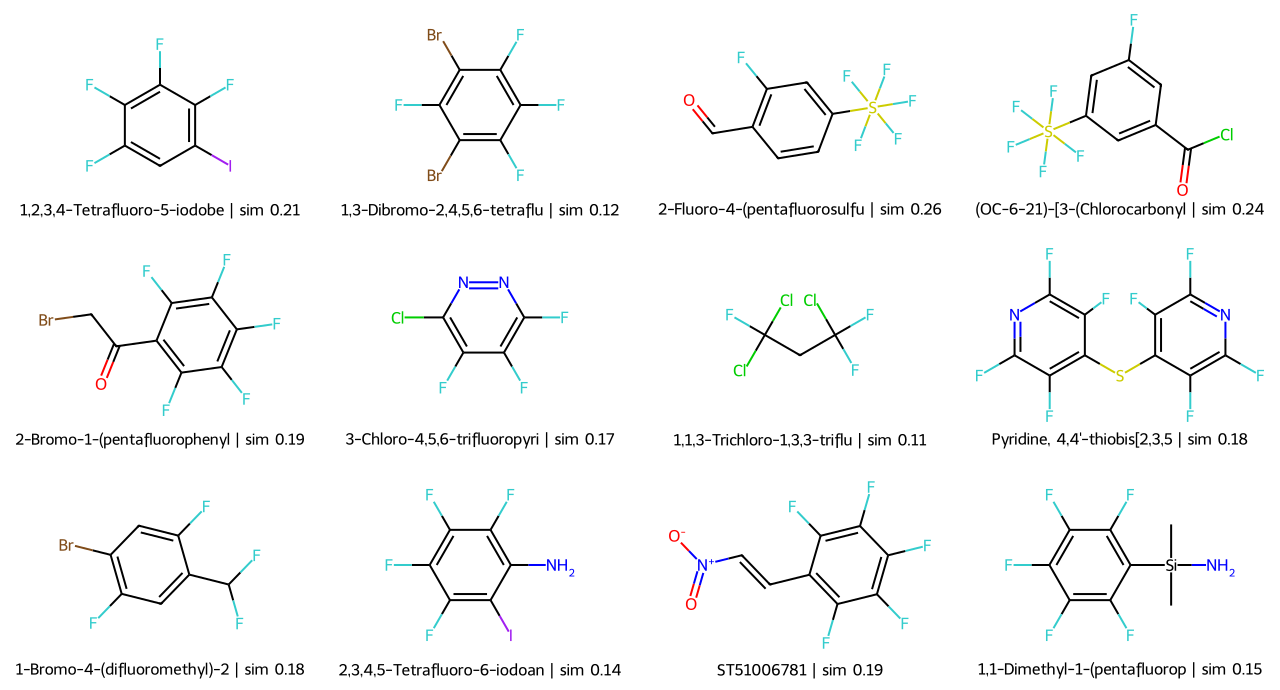

In [13]:
def show(sub, title, n=12, seed=0):
    sub = sub.sample(min(n, len(sub)), random_state=seed)
    legends = [f"{r.get('PREFERRED NAME', '')[:28]} | sim {r.max_sim:.2f}" for _, r in sub.iterrows()]
    print(title)
    return Draw.MolsToGridImage(list(sub["mol"]), molsPerRow=4, subImgSize=(320, 230),
                                legends=legends)

show(z, "Random sample of the 0-carbon group")

Unclassified


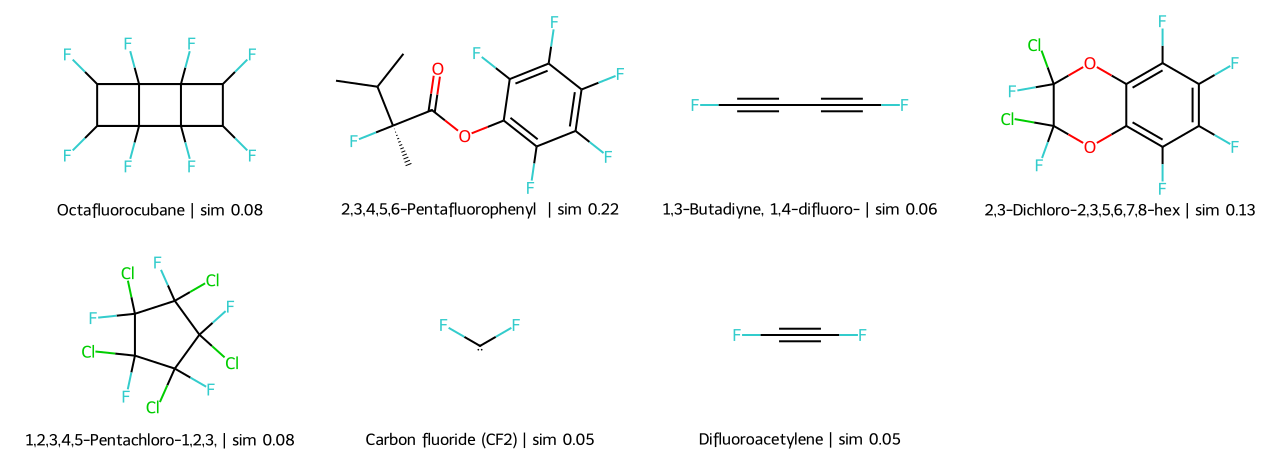

In [14]:
show(z[z["primary"] == "other / unclassified"], "Unclassified")

In [15]:
df_train = pd.read_parquet(root / "data/processed/lipo_curated.parquet")
train_heavy = df_train["smiles"].map(lambda s: Chem.MolFromSmiles(s).GetNumHeavyAtoms())
print("training heavy atoms: median", train_heavy.median(),
      "| 1st-99th pct", train_heavy.quantile([.01, .99]).tolist())

bins = [0, 10, 15, 20, 25, 35, 50, 10_000]
d["size_bin"] = pd.cut(d["heavy_atoms"], bins)
d["group"] = np.where(d["zero_cf"], "0 CF carbons", "1+ CF carbons")
tab = (d.groupby(["size_bin", "group"], observed=True)["max_sim"]
         .agg(n="size", median="median").round(3).unstack("group"))
print(tab)
print(d.groupby("group")[["heavy_atoms", "mol_wt", "n_F"]].median())

training heavy atoms: median 27.0 | 1st-99th pct [11.0, 44.0]
                       n                     median              
group       0 CF carbons 1+ CF carbons 0 CF carbons 1+ CF carbons
size_bin                                                         
(0, 10]              674          1880        0.138         0.157
(10, 15]             510          3077        0.182         0.188
(15, 20]             159          3674        0.188         0.222
(20, 25]             154          2410        0.152         0.200
(25, 35]             120          3462        0.188         0.200
(35, 50]              56          2396        0.142         0.209
(50, 10000]           19           939        0.122         0.188
               heavy_atoms    mol_wt  n_F
group                                    
0 CF carbons          12.0  214.2875  4.0
1+ CF carbons         21.0  350.0490  8.0


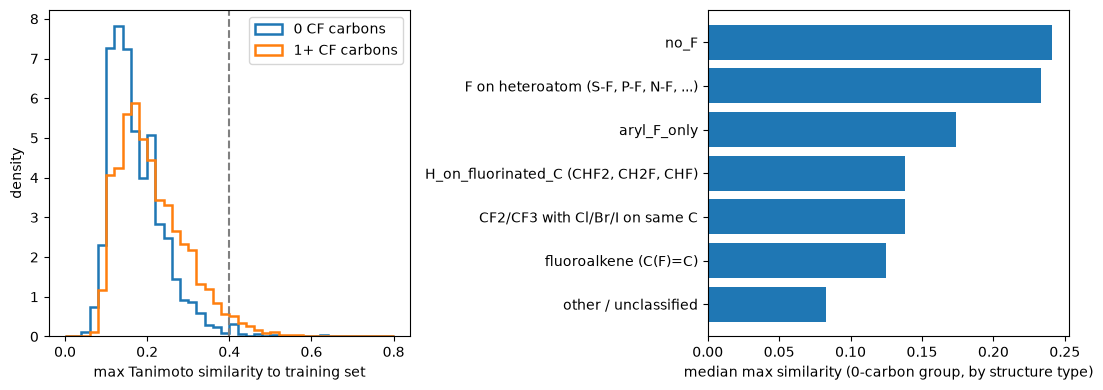

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bins_sim = np.linspace(0, 0.8, 41)
for lab, g in d.groupby("group"):
    axes[0].hist(g["max_sim"], bins=bins_sim, density=True, histtype="step", lw=1.8, label=lab)
axes[0].axvline(0.4, color="grey", ls="--")
axes[0].set_xlabel("max Tanimoto similarity to training set")
axes[0].set_ylabel("density"); axes[0].legend()

s = summary.sort_values("median_max_sim")
axes[1].barh(s.index, s["median_max_sim"])
axes[1].set_xlabel("median max similarity (0-carbon group, by structure type)")
fig.tight_layout()
fig.savefig(root / "results/figures/pfas_zero_cf_group.png", dpi=200)

In [17]:
# Check the reason for the 0-carbon group
def n_F(smi):
    return sum(a.GetAtomicNum() == 9 for a in Chem.MolFromSmiles(smi).GetAtoms())

chk = pfas.copy()                     # keeps the raw "SMILES" column from load_pfas
chk["F_raw"], chk["F_std"] = chk["SMILES"].map(n_F), chk["smiles"].map(n_F)
lost = chk[chk["F_std"] < chk["F_raw"]]
print(len(lost), "lost fluorine;", (chk["F_std"] == 0).sum(), "ended with none")
print(lost[["PREFERRED NAME", "SMILES", "smiles"]].head(15).to_string())

243 lost fluorine; 123 ended with none
                                                                                                                                           PREFERRED NAME                                                                                                                                                                                                                                                                                                                                                                                                                                      SMILES                                                                                                                                    smiles
139                                                                                    N-Ethyl-N-[3-(trimethoxysilyl)propyl]perfluoro-1-butanesulfonamide                                                                                        